In [ ]:
#################################################################
###      Installing the Libraries required for the plotting       ###
#################################################################

!pip install pandas
!pip install numpy
!pip install matplotlib
!pip install seaborn

In [ ]:
#################################################################
###      Import the Libraries required for the plotting       ###
#################################################################

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Visualisation settings
sns.set_theme(style="whitegrid", palette="deep")

plt.rcParams["figure.figsize"] = (10, 6)

pd.set_option("display.max_columns", None)

In [6]:
from pathlib import Path

candidates = [
    Path("Data/diabetic_data.csv"),
    Path("../Data/diabetic_data.csv"),
]

csv_path = next((path for path in candidates if path.is_file()), None)

if csv_path is None:
    raise FileNotFoundError(
        f"Could not find diabetic_data.csv. Current working directory: {Path.cwd()}"
    )

df = pd.read_csv(csv_path)

# Display first five records
display(df.head())

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [7]:
print("Number of hospital encounters:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Number of unique patients:", df["patient_nbr"].nunique())

print("\nDataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

Number of hospital encounters: 101766
Number of columns: 50
Number of unique patients: 71518

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures      

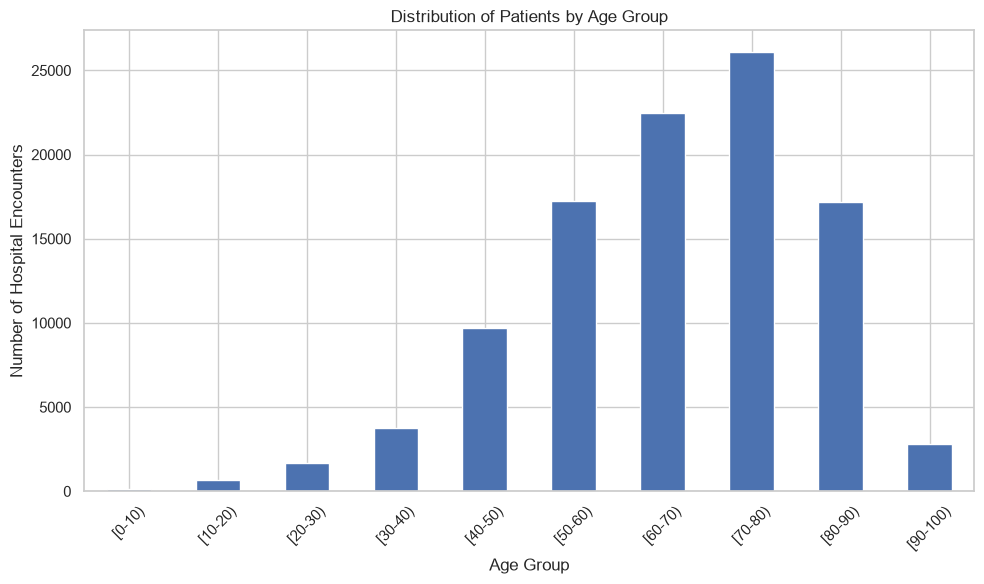

In [ ]:
####################################################################################
###      1. Bar graphs representation showing patients distribution by age       ###
####################################################################################


plt.figure(figsize=(10, 6))

age_counts = df['age'].value_counts().sort_index()

age_counts.plot(kind='bar')

plt.title('Distribution of Patients by Age Group')

plt.xlabel('Age Group')

plt.ylabel('Number of Hospital Encounters')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

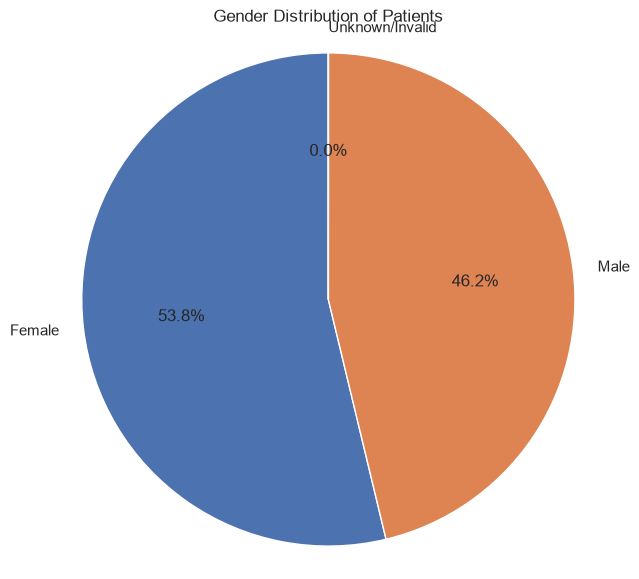

In [ ]:
####################################################################################
###      2. Pie chart showing gender distribution.                               ###
####################################################################################


gender_counts = df['gender'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(

    gender_counts,

    labels=gender_counts.index,

    autopct='%1.1f%%',

    startangle=90

)

plt.title('Gender Distribution of Patients')

plt.axis('equal')

plt.show()


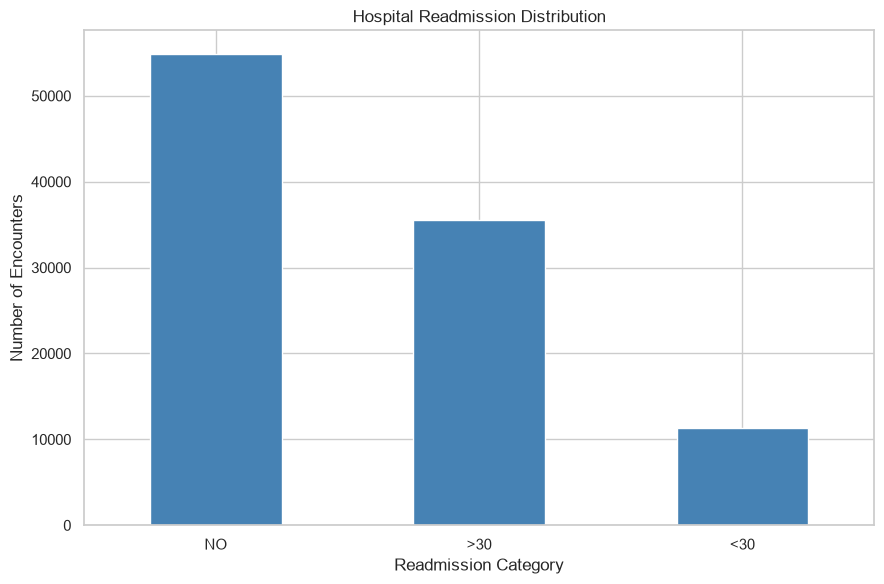

In [ ]:
####################################################################################
###      3.Bar graphs showing hospital readmissions.                             ###
####################################################################################

readmission_counts = df['readmitted'].value_counts()

plt.figure(figsize=(9, 6))

readmission_counts.plot(
    kind='bar',
    color='steelblue'
)

plt.title('Hospital Readmission Distribution')
plt.xlabel('Readmission Category')
plt.ylabel('Number of Encounters')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


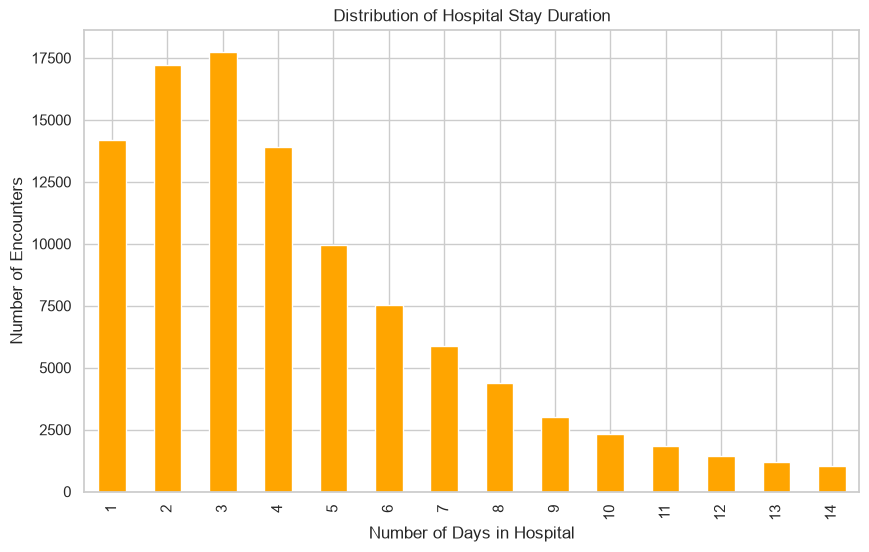

In [ ]:
####################################################################################
###      4.Bar graph showing hospital stay duration.                             ###
####################################################################################

stay_counts = df['time_in_hospital'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

stay_counts.plot(kind='bar', color='orange')

plt.title('Distribution of Hospital Stay Duration')
plt.xlabel('Number of Days in Hospital')
plt.ylabel('Number of Encounters')
plt.show()


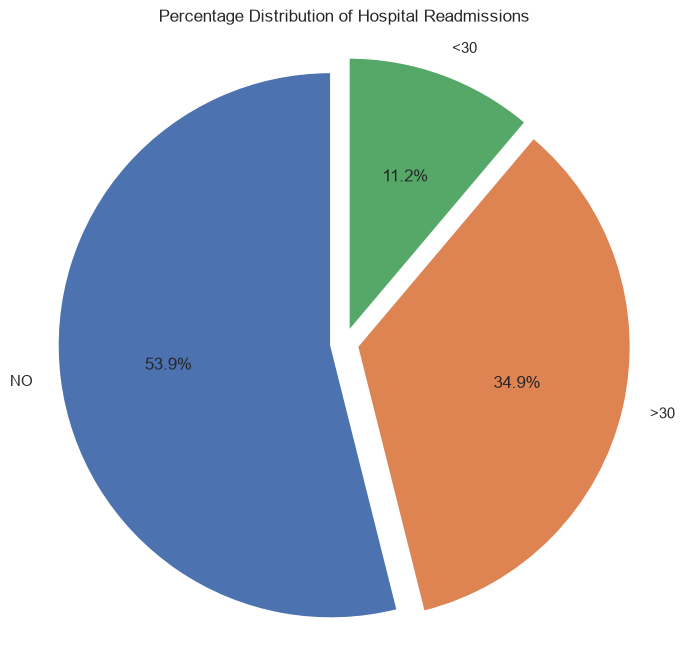

In [ ]:
####################################################################################
###      5.Piechart showing readmission percentage                               ###
####################################################################################

plt.figure(figsize=(8, 8))

plt.pie(
    readmission_counts,
    labels=readmission_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    explode=[0.05] * len(readmission_counts)
)

plt.title('Percentage Distribution of Hospital Readmissions')
plt.axis('equal')

plt.show()


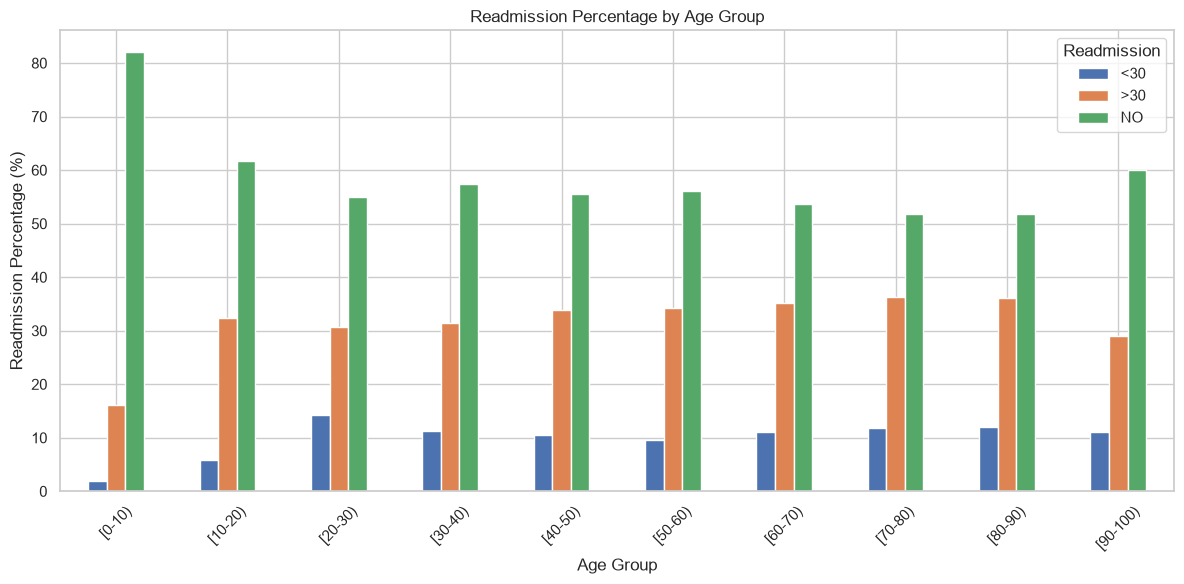

In [ ]:
####################################################################################
###      6.Bar graph comparing readmission by age grou                           ###
####################################################################################

age_readmission = pd.crosstab(
    df['age'],
    df['readmitted'],
    normalize='index'
) * 100

age_readmission.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Readmission Percentage by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Readmission Percentage (%)')
plt.xticks(rotation=45)
plt.legend(title='Readmission')

plt.tight_layout()
plt.show()
